In [103]:
import pandas as pd
import numpy as np

path = "data/ml-100k"

ratings = pd.read_csv(
    f"{path}/u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

genre_cols_raw = [
    "unknown", "Action", "Adventure", "Animation", "Children's",
    "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western"
]

item_cols = [
    "item_id", "title", "release_date", "video_release_date", "imdb_url"
] + genre_cols_raw

items = pd.read_csv(
    f"{path}/u.item",
    sep="|",
    names=item_cols,
    encoding="latin-1"
)

# remove unknown
genre_cols = [g for g in genre_cols_raw if g != "unknown"]

genre2idx = {g: k for k, g in enumerate(genre_cols)}
G = len(genre_cols)  # MovieLens 100k: 18

def item_genre_indices(row):
    return [
        genre2idx[g]
        for g in genre_cols
        if row[g] == 1
    ]

items["genre_ids"] = items.apply(item_genre_indices, axis=1)

item_genres = dict(zip(items["item_id"], items["genre_ids"]))

warm start temporal split

In [104]:
def split_by_user_time(df, train_ratio=0.8, val_ratio=0.1, min_n=5):
    train, val, test = [], [], []

    for uid, d in df.sort_values("timestamp").groupby("user_id"):
        d = d.sort_values("timestamp")
        n = len(d)

        if n < min_n:
            train.append(d)
            continue

        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)

        train.append(d.iloc[:n_train])
        val.append(d.iloc[n_train:n_train+n_val])
        test.append(d.iloc[n_train+n_val:])

    return (
        pd.concat(train).reset_index(drop=True),
        pd.concat(val).reset_index(drop=True),
        pd.concat(test).reset_index(drop=True),
    )

train, val, test = split_by_user_time(ratings)

estimate mu, bi, bu

In [105]:
mu = train["rating"].mean()

user_mean = train.groupby("user_id")["rating"].mean()
item_mean = train.groupby("item_id")["rating"].mean()

b_u = (user_mean - mu).to_dict()
b_i = (item_mean - mu).to_dict()

def add_residual(df):
    df = df.copy()
    df["bu_stat"] = df["user_id"].map(b_u).fillna(0.0)
    df["bi_stat"] = df["item_id"].map(b_i).fillna(0.0)
    df["E"] = df["rating"] - mu - df["bu_stat"] - df["bi_stat"]
    return df

train = add_residual(train)
val = add_residual(val)
test = add_residual(test)
train

,user_id,item_id,rating,timestamp,bu_stat,bi_stat,E
0,1,168,5,874965478,0.013742,0.463228,0.942302
1,1,172,5,874965478,0.013742,0.595029,0.810501
2,1,165,5,874965518,0.013742,0.604457,0.801073
3,1,156,4,874965556,0.013742,0.411459,-0.005929
4,1,166,5,874965677,0.013742,0.536919,0.868611
...,...,...,...,...,...,...,...
79614,943,139,1,888640027,0.016287,-0.685991,-1.911024
79615,943,426,4,888640027,0.016287,-0.455728,0.858713
79616,943,720,1,888640048,0.016287,-0.484574,-2.112441
79617,943,80,2,888640048,0.016287,-0.657651,-0.939364


User taste T_u

In [106]:
from collections import defaultdict
import numpy as np


from collections import defaultdict
import numpy as np

def build_user_taste_residual_lift(
    train,
    item_genres,
    G,
    mu,
    beta=10.0,
    min_count=2
):
    """
    Build user taste type T_u using residual lift.

    T_u = argmax_g shrinked average residual for user u on genre g.

    residual = rating - mu - bu_stat - bi_stat

    Parameters
    ----------
    train : pd.DataFrame
        Must contain columns:
        user_id, item_id, rating, bu_stat, bi_stat

    item_genres : dict
        item_id -> list of genre indices

    G : int
        Number of genres

    mu : float
        Global mean rating

    beta : float
        Shrinkage strength. Larger beta means stronger shrink toward 0.

    min_count : int
        Minimum effective count required for a genre to be considered.
    """

    user_sum = defaultdict(lambda: np.zeros(G, dtype=float))
    user_count = defaultdict(lambda: np.zeros(G, dtype=float))

    for row in train.itertuples():
        gs = item_genres.get(row.item_id, [])

        if len(gs) == 0:
            continue

        residual = row.rating - mu - row.bu_stat - row.bi_stat

        w = 1.0 / len(gs)

        for g in gs:
            user_sum[row.user_id][g] += w * residual
            user_count[row.user_id][g] += w

    user_T = {}

    for uid in train["user_id"].unique():
        sums = user_sum[uid]
        counts = user_count[uid]

        avg_residual = np.divide(
            sums,
            counts,
            out=np.zeros(G, dtype=float),
            where=counts > 0
        )

        shrink = counts / (counts + beta)
        score = shrink * avg_residual

        valid = counts >= min_count

        if valid.sum() > 0:
            score[~valid] = -np.inf
            user_T[uid] = int(np.argmax(score))
        else:
            # fallback: use most observed genre
            if counts.sum() > 0:
                user_T[uid] = int(np.argmax(counts))
            else:
                user_T[uid] = 0

    return user_T


user_T = build_user_taste_residual_lift(
    train=train,
    item_genres=item_genres,
    G=G,
    mu=mu,
    beta=10.0,
    min_count=2
)


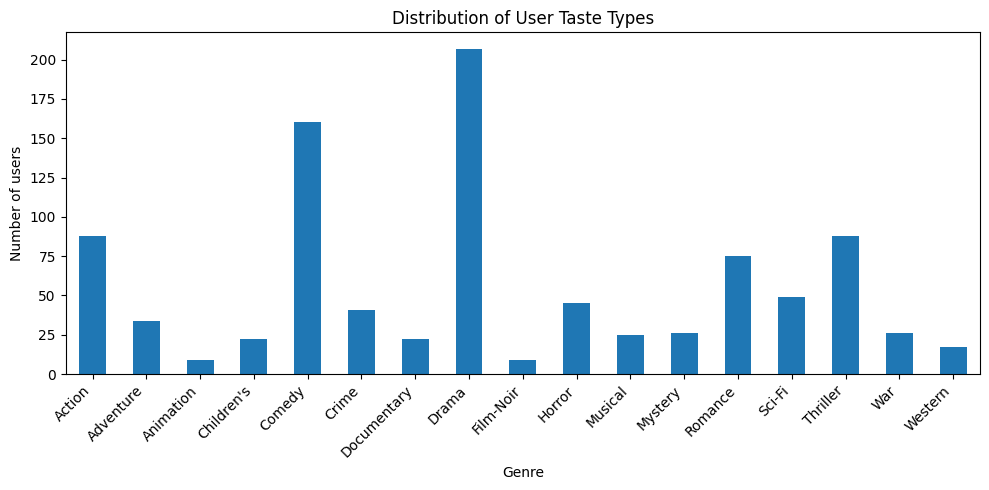

In [107]:


import matplotlib.pyplot as plt
import pandas as pd

dist = pd.Series(user_T).value_counts().sort_index()
dist.index = [genre_cols[i] for i in dist.index]

plt.figure(figsize=(10, 5))
dist.plot(kind="bar")

plt.xlabel("Genre")
plt.ylabel("Number of users")
plt.title("Distribution of User Taste Types")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

residual bins

In [108]:
B = 8

edges = np.quantile(train["E"], np.linspace(0, 1, B + 1))
edges[0] -= 1e-6
edges[-1] += 1e-6
centers = 0.5 * (edges[:-1] + edges[1:])

def add_E_bin(df):
    df = df.copy()
    df["E_bin"] = np.digitize(df["E"].values, edges[1:-1])
    return df

train = add_E_bin(train)
val = add_E_bin(val)
test = add_E_bin(test)

build p(E|T,g)

In [109]:
def build_prior_E_given_Tg(train, movie_genres, user_T, G, B, alpha=50.0):
    counts = np.zeros((G, G, B), dtype=float)
    # first axis: T, second axis: genre g, third: residual bin

    for row in train.itertuples():
        T = user_T.get(row.user_id, 0)
        gs = movie_genres.get(row.item_id, [])
        e = int(row.E_bin)

        if len(gs) == 0:
            continue

        w = 1.0 / len(gs)
        for g in gs:
            counts[T, g, e] += w

    global_E = counts.sum(axis=(0, 1))
    global_E = global_E / global_E.sum()

    prior = np.zeros_like(counts)

    for T in range(G):
        for g in range(G):
            n = counts[T, g].sum()
            prior[T, g] = (counts[T, g] + alpha * global_E) / (n + alpha)

    return prior

prior_TgE = build_prior_E_given_Tg(train, item_genres, user_T, G, B, alpha=50.0)

prior_TgE.shape
# classical conditional probability table / prior table

(18, 18, 8)

## Model

In [110]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class MF(nn.Module):
    def __init__(self, n_users, n_items, k=64, mu=3.5):
        super().__init__()
        self.P = nn.Embedding(n_users, k)
        self.Q = nn.Embedding(n_items, k)
        self.bu = nn.Embedding(n_users, 1)
        self.bi = nn.Embedding(n_items, 1)
        self.mu = nn.Parameter(torch.tensor(float(mu)))

        nn.init.normal_(self.P.weight, std=0.05)
        nn.init.normal_(self.Q.weight, std=0.05)
        nn.init.zeros_(self.bu.weight)
        nn.init.zeros_(self.bi.weight)

    def forward(self, u, i):
        dot = (self.P(u) * self.Q(i)).sum(dim=1)
        return self.mu + self.bu(u).squeeze(1) + self.bi(i).squeeze(1) + dot

In [111]:
class MFDataset(Dataset):
    def __init__(self, df, user2idx, item2idx, user_T, item_genres, G):
        self.u_raw = df["user_id"].values
        self.i_raw = df["item_id"].values

        self.u = df["user_id"].map(user2idx).values.astype("int64")
        self.i = df["item_id"].map(item2idx).values.astype("int64")
        self.r = df["rating"].values.astype("float32")

        self.bu_stat = df["bu_stat"].values.astype("float32")
        self.bi_stat = df["bi_stat"].values.astype("float32")

        self.T = np.array(
            [user_T.get(u, 0) for u in self.u_raw],
            dtype="int64"
        )

        genre_masks = []

        for item_id in self.i_raw:
            mask = np.zeros(G, dtype="float32")
            gs = item_genres.get(item_id, [])

            if len(gs) > 0:
                for g in gs:
                    mask[g] = 1.0 / len(gs)
            else:
                mask[0] = 1.0

            genre_masks.append(mask)

        self.genre_mask = np.stack(genre_masks)

    def __len__(self):
        return len(self.r)

    def __getitem__(self, idx):
        return {
            "u": torch.tensor(self.u[idx]).long(),
            "i": torch.tensor(self.i[idx]).long(),
            "r": torch.tensor(self.r[idx]).float(),
            "bu_stat": torch.tensor(self.bu_stat[idx]).float(),
            "bi_stat": torch.tensor(self.bi_stat[idx]).float(),
            "T": torch.tensor(self.T[idx]).long(),
            "genre_mask": torch.tensor(self.genre_mask[idx]).float(),
        }

In [112]:
def soft_bin(x, centers, tau=0.1):
    # x: [batch]
    # centers: [B]
    dist2 = (x[:, None] - centers[None, :]) ** 2
    return torch.softmax(-dist2 / tau, dim=1)


def prior_loss(pred_rating, batch, mu_fixed, centers_t, prior_TgE_t, tau=0.1, eps=1e-8):
    """
    prior_TgE_t: [T=18, g=18, E=8]
    genre_mask: [batch, 18], each row sums to 1
    """

    pred_E = pred_rating - mu_fixed - batch["bu_stat"] - batch["bi_stat"]
    q_E = soft_bin(pred_E, centers_t, tau=tau)  # [batch, B]

    T = batch["T"]  # [batch]
    prior_for_T = prior_TgE_t[T]  # [batch, G, B]

    # Average genre priors according to movie genre mask
    # p_E[b] = sum_g genre_mask[g] * p(E | T, g)
    p_E = torch.einsum("bg,bge->be", batch["genre_mask"], prior_for_T)

    loss = -(q_E * torch.log(p_E + eps)).sum(dim=1).mean()
    return loss

## Training

In [113]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd

In [114]:
user_ids = sorted(train["user_id"].unique())
item_ids = sorted(train["item_id"].unique())

user2idx = {u: idx for idx, u in enumerate(user_ids)}
item2idx = {i: idx for idx, i in enumerate(item_ids)}

n_users = len(user2idx)
n_items = len(item2idx)

def keep_known_users_items(df, user2idx, item2idx):
    return df[
        df["user_id"].isin(user2idx) &
        df["item_id"].isin(item2idx)
    ].reset_index(drop=True)

train_eval = keep_known_users_items(train, user2idx, item2idx)
val_eval = keep_known_users_items(val, user2idx, item2idx)
test_eval = keep_known_users_items(test, user2idx, item2idx)

print(len(train), len(train_eval))
print(len(val), len(val_eval))
print(len(test), len(test_eval))

79619 79619
9596 9558
10785 10736


In [115]:
# DataLoader

batch_size = 1024

train_ds = MFDataset(train_eval, user2idx, item2idx, user_T, item_genres, G)
val_ds = MFDataset(val_eval, user2idx, item2idx, user_T, item_genres, G)
test_ds = MFDataset(test_eval, user2idx, item2idx, user_T, item_genres, G)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

In [116]:
# Evaluation function：RMSE / MAE

@torch.no_grad()
def evaluate_model(model, loader, clip=True):
    device = next(model.parameters()).device
    model.eval()

    preds = []
    trues = []

    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        pred = model(batch["u"], batch["i"])

        if clip:
            pred = torch.clamp(pred, 1.0, 5.0)

        preds.append(pred.cpu().numpy())
        trues.append(batch["r"].cpu().numpy())

    preds = np.concatenate(preds)
    trues = np.concatenate(trues)

    rmse = np.sqrt(np.mean((preds - trues) ** 2))
    mae = np.mean(np.abs(preds - trues))

    return {
        "rmse": rmse,
        "mae": mae,
    }

In [117]:
def train_model(
    model,
    train_loader,
    val_loader=None,
    prior_TgE=None,
    lambda_q=0.0,
    epochs=20,
    lr=1e-3,
    weight_decay=1e-5,
):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)

    opt = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    mse_fn = nn.MSELoss()

    centers_t = torch.tensor(centers, dtype=torch.float32, device=device)
    mu_fixed = torch.tensor(float(mu), dtype=torch.float32, device=device)

    if prior_TgE is not None:
        prior_TgE_t = torch.tensor(prior_TgE, dtype=torch.float32, device=device)
    else:
        prior_TgE_t = None

    history = []

    for epoch in range(1, epochs + 1):
        model.train()

        total_mse = 0.0
        total_prior = 0.0
        total_loss = 0.0

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            pred = model(batch["u"], batch["i"])

            mse = mse_fn(pred, batch["r"])
            loss = mse

            pl = torch.tensor(0.0, device=device)

            if prior_TgE_t is not None and lambda_q > 0:
                pl = prior_loss(
                    pred,
                    batch,
                    mu_fixed=mu_fixed,
                    centers_t=centers_t,
                    prior_TgE_t=prior_TgE_t,
                    tau=0.1,
                )
                loss = mse + lambda_q * pl

            opt.zero_grad()
            loss.backward()
            opt.step()

            total_mse += mse.item()
            total_prior += pl.item()
            total_loss += loss.item()

        avg_mse = total_mse / len(train_loader)
        avg_prior = total_prior / len(train_loader)
        avg_loss = total_loss / len(train_loader)

        row = {
            "epoch": epoch,
            "train_mse": avg_mse,
            "train_rmse": np.sqrt(avg_mse),
            "train_prior": avg_prior,
            "train_loss": avg_loss,
        }

        if val_loader is not None:
            val_metrics = evaluate_model(model, val_loader, clip=True)
            row["val_rmse"] = val_metrics["rmse"]
            row["val_mae"] = val_metrics["mae"]

            print(
                f"epoch {epoch:02d} | "
                f"train_rmse={row['train_rmse']:.4f} | "
                f"prior={avg_prior:.4f} | "
                f"val_rmse={row['val_rmse']:.4f} | "
                f"val_mae={row['val_mae']:.4f}"
            )
        else:
            print(
                f"epoch {epoch:02d} | "
                f"train_rmse={row['train_rmse']:.4f} | "
                f"prior={avg_prior:.4f}"
            )

        history.append(row)

    history = pd.DataFrame(history)

    return model, history

-------------------

In [ ]:
def run_one_experiment(
    exp_name,
    user_T_exp,
    lambda_q,
    alpha=50.0,
    epochs=20,
    seed=42
):
    torch.manual_seed(seed)
    np.random.seed(seed)

    prior_TgE_exp = build_prior_E_given_Tg(
        train=train,
        movie_genres=item_genres,
        user_T=user_T_exp,
        G=G,
        B=B,
        alpha=alpha
    )

    train_ds = MFDataset(train_eval, user2idx, item2idx, user_T_exp, item_genres, G)
    val_ds = MFDataset(val_eval, user2idx, item2idx, user_T_exp, item_genres, G)
    test_ds = MFDataset(test_eval, user2idx, item2idx, user_T_exp, item_genres, G)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    model = MF(
        n_users=n_users,
        n_items=n_items,
        k=64,
        mu=mu
    )

    use_prior = lambda_q > 0

    model, hist = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        prior_TgE=prior_TgE_exp if use_prior else None,
        lambda_q=lambda_q,
        epochs=epochs,
        lr=1e-3,
        weight_decay=1e-5
    )

    val_metrics = evaluate_model(model, val_loader)
    test_metrics = evaluate_model(model, test_loader)

    result = {
        "experiment": exp_name,
        "lambda_q": lambda_q,
        "alpha": alpha,
        "val_rmse": val_metrics["rmse"],
        "val_mae": val_metrics["mae"],
        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],
        "best_val_rmse": hist["val_rmse"].min(),
        "best_epoch": int(hist.loc[hist["val_rmse"].idxmin(), "epoch"])
    }

    return model, hist, result, prior_TgE_exp

In [126]:
def shuffle_user_T(user_T, seed=42):
    rng = np.random.default_rng(seed)

    users = np.array(list(user_T.keys()))
    values = np.array(list(user_T.values()))

    shuffled_values = values.copy()
    rng.shuffle(shuffled_values)

    return dict(zip(users, shuffled_values))


user_T_shuffled = shuffle_user_T(user_T, seed=42)

In [ ]:
# baseline and prior grid search

lambda_grid = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1]

real_results = []
real_histories = {}
real_models = {}

for lambda_q in lambda_grid:
    exp_name = f"real_prior_lambda_{lambda_q}"

    model, hist, result, prior_exp = run_one_experiment(
        exp_name=exp_name,
        user_T_exp=user_T,
        lambda_q=lambda_q,
        alpha=50.0,
        epochs=20,
        seed=42
    )

    real_results.append(result)
    real_histories[lambda_q] = hist
    real_models[lambda_q] = model

real_results_df = pd.DataFrame(real_results).sort_values("val_rmse")
real_results_df

epoch 01 | train_rmse=1.0947 | prior=0.0000 | val_rmse=1.1639 | val_mae=0.9650
epoch 02 | train_rmse=1.0672 | prior=0.0000 | val_rmse=1.1442 | val_mae=0.9464
epoch 03 | train_rmse=1.0399 | prior=0.0000 | val_rmse=1.1244 | val_mae=0.9263
epoch 04 | train_rmse=1.0085 | prior=0.0000 | val_rmse=1.1000 | val_mae=0.9013
epoch 05 | train_rmse=0.9689 | prior=0.0000 | val_rmse=1.0720 | val_mae=0.8701
epoch 06 | train_rmse=0.9232 | prior=0.0000 | val_rmse=1.0417 | val_mae=0.8377
epoch 07 | train_rmse=0.8771 | prior=0.0000 | val_rmse=1.0177 | val_mae=0.8131
epoch 08 | train_rmse=0.8344 | prior=0.0000 | val_rmse=0.9995 | val_mae=0.7958
epoch 09 | train_rmse=0.7952 | prior=0.0000 | val_rmse=0.9875 | val_mae=0.7844
epoch 10 | train_rmse=0.7593 | prior=0.0000 | val_rmse=0.9800 | val_mae=0.7769
epoch 11 | train_rmse=0.7261 | prior=0.0000 | val_rmse=0.9757 | val_mae=0.7723
epoch 12 | train_rmse=0.6949 | prior=0.0000 | val_rmse=0.9735 | val_mae=0.7697
epoch 13 | train_rmse=0.6659 | prior=0.0000 | val_rm

,experiment,lambda_q,alpha,val_rmse,val_mae,test_rmse,test_mae,best_val_rmse,best_epoch
5,real_prior_lambda_0.1,0.100,50.0,0.991110,0.779856,1.032916,0.819364,0.973211,13
4,real_prior_lambda_0.03,0.030,50.0,0.991217,0.779984,1.033037,0.819550,0.973225,13
3,real_prior_lambda_0.01,0.010,50.0,0.991251,0.780023,1.033062,0.819600,0.973234,13
2,real_prior_lambda_0.003,0.003,50.0,0.991265,0.780040,1.033070,0.819618,0.973239,13
1,real_prior_lambda_0.001,0.001,50.0,0.991268,0.780044,1.033072,0.819623,0.973240,13
0,real_prior_lambda_0.0,0.000,50.0,0.991270,0.780046,1.033073,0.819625,0.973240,13


In [129]:
baseline_row = real_results_df[real_results_df["lambda_q"] == 0.0].iloc[0]
best_real_row = real_results_df[real_results_df["lambda_q"] > 0].iloc[0]

best_lambda = best_real_row["lambda_q"]

print("Best lambda:", best_lambda)
print("Baseline val RMSE:", baseline_row["val_rmse"])
print("Best prior val RMSE:", best_real_row["val_rmse"])

Best lambda: 0.1
Baseline val RMSE: 0.9912698
Best prior val RMSE: 0.99110955


In [130]:
shuffled_model, shuffled_hist, shuffled_result, shuffled_prior_TgE = run_one_experiment(
    exp_name="shuffled_T_prior",
    user_T_exp=user_T_shuffled,
    lambda_q=best_lambda,
    alpha=50.0,
    epochs=20,
    seed=42
)

epoch 01 | train_rmse=1.0947 | prior=2.0788 | val_rmse=1.1640 | val_mae=0.9650
epoch 02 | train_rmse=1.0672 | prior=2.0789 | val_rmse=1.1444 | val_mae=0.9464
epoch 03 | train_rmse=1.0399 | prior=2.0789 | val_rmse=1.1245 | val_mae=0.9263
epoch 04 | train_rmse=1.0084 | prior=2.0787 | val_rmse=1.1001 | val_mae=0.9013
epoch 05 | train_rmse=0.9689 | prior=2.0785 | val_rmse=1.0721 | val_mae=0.8700
epoch 06 | train_rmse=0.9232 | prior=2.0786 | val_rmse=1.0418 | val_mae=0.8377
epoch 07 | train_rmse=0.8771 | prior=2.0789 | val_rmse=1.0178 | val_mae=0.8131
epoch 08 | train_rmse=0.8344 | prior=2.0789 | val_rmse=0.9995 | val_mae=0.7958
epoch 09 | train_rmse=0.7952 | prior=2.0790 | val_rmse=0.9876 | val_mae=0.7844
epoch 10 | train_rmse=0.7594 | prior=2.0790 | val_rmse=0.9801 | val_mae=0.7769
epoch 11 | train_rmse=0.7261 | prior=2.0789 | val_rmse=0.9758 | val_mae=0.7723
epoch 12 | train_rmse=0.6949 | prior=2.0789 | val_rmse=0.9736 | val_mae=0.7697
epoch 13 | train_rmse=0.6660 | prior=2.0787 | val_rm

In [131]:
# baseline vs real prior vs shuffled prior

summary_df = pd.DataFrame([
    {
        "experiment": "baseline",
        "lambda_q": 0.0,
        "val_rmse": baseline_row["val_rmse"],
        "val_mae": baseline_row["val_mae"],
        "test_rmse": baseline_row["test_rmse"],
        "test_mae": baseline_row["test_mae"],
    },
    {
        "experiment": "real_prior",
        "lambda_q": best_lambda,
        "val_rmse": best_real_row["val_rmse"],
        "val_mae": best_real_row["val_mae"],
        "test_rmse": best_real_row["test_rmse"],
        "test_mae": best_real_row["test_mae"],
    },
    {
        "experiment": "shuffled_T_prior",
        "lambda_q": best_lambda,
        "val_rmse": shuffled_result["val_rmse"],
        "val_mae": shuffled_result["val_mae"],
        "test_rmse": shuffled_result["test_rmse"],
        "test_mae": shuffled_result["test_mae"],
    }
])

baseline_test_rmse = summary_df.loc[
    summary_df["experiment"] == "baseline",
    "test_rmse"
].iloc[0]

summary_df["test_rmse_improvement_vs_baseline"] = (
    baseline_test_rmse - summary_df["test_rmse"]
)

summary_df.round(5)

,experiment,lambda_q,val_rmse,val_mae,test_rmse,test_mae,test_rmse_improvement_vs_baseline
0,baseline,0.0,0.99127,0.78005,1.03307,0.81963,0.00000
1,real_prior,0.1,0.99111,0.77986,1.03292,0.81936,0.00016
2,shuffled_T_prior,0.1,0.99124,0.77996,1.03303,0.81957,0.00005


In [133]:
# cold users
user_train_count = train.groupby("user_id").size()
item_train_count = train.groupby("item_id").size()

def add_frequency_groups(df):
    df = df.copy()

    df["user_train_count"] = df["user_id"].map(user_train_count).fillna(0)
    df["item_train_count"] = df["item_id"].map(item_train_count).fillna(0)

    df["cold_user"] = df["user_train_count"] <= 20
    df["long_tail_item"] = df["item_train_count"] <= 20

    return df

@torch.no_grad()
def predict_df(model, df, user2idx, item2idx, clip=True):
    """
    Predict ratings for a dataframe and return dataframe with pred and err.

    Required columns:
        user_id, item_id, rating
    """

    device = next(model.parameters()).device
    model.eval()

    df = df.copy()

    # 只保留 train 里见过的 user/item
    df = df[
        df["user_id"].isin(user2idx) &
        df["item_id"].isin(item2idx)
    ].reset_index(drop=True)

    if len(df) == 0:
        df["pred"] = []
        df["err"] = []
        return df

    u = torch.tensor(
        df["user_id"].map(user2idx).values,
        dtype=torch.long,
        device=device
    )

    i = torch.tensor(
        df["item_id"].map(item2idx).values,
        dtype=torch.long,
        device=device
    )

    pred = model(u, i)

    if clip:
        pred = torch.clamp(pred, 1.0, 5.0)

    df["pred"] = pred.detach().cpu().numpy()
    df["err"] = df["pred"] - df["rating"]

    return df

@torch.no_grad()
def rmse_on_subset(model, df_subset):
    if len(df_subset) == 0:
        return np.nan

    pred_df = predict_df(model, df_subset, user2idx, item2idx)

    return np.sqrt(np.mean((pred_df["pred"] - pred_df["rating"]) ** 2))

test_grouped = add_frequency_groups(test_eval)

subgroup_rows = []

for group_name, mask in [
    ("all", np.ones(len(test_grouped), dtype=bool)),
    ("cold_user", test_grouped["cold_user"].values),
    ("warm_user", ~test_grouped["cold_user"].values),
    ("long_tail_item", test_grouped["long_tail_item"].values),
    ("popular_item", ~test_grouped["long_tail_item"].values),
    ("cold_user_or_long_tail", (
        test_grouped["cold_user"] | test_grouped["long_tail_item"]
    ).values),
]:
    d = test_grouped[mask]

    baseline_rmse = rmse_on_subset(real_models[0.0], d)
    prior_rmse = rmse_on_subset(real_models[best_lambda], d)
    shuffled_rmse = rmse_on_subset(shuffled_model, d)

    subgroup_rows.append({
        "group": group_name,
        "n": len(d),
        "baseline_rmse": baseline_rmse,
        "prior_rmse": prior_rmse,
        "shuffled_prior_rmse": shuffled_rmse,
        "prior_improvement": baseline_rmse - prior_rmse,
        "shuffled_improvement": baseline_rmse - shuffled_rmse,
    })

subgroup_df = pd.DataFrame(subgroup_rows)
subgroup_df.round(5)

,group,n,baseline_rmse,prior_rmse,shuffled_prior_rmse,prior_improvement,shuffled_improvement
0,all,10736,1.03307,1.03292,1.03303,0.00016,0.00005
1,cold_user,455,1.12494,1.12439,1.12487,0.00055,0.00007
2,warm_user,10281,1.02882,1.02868,1.02877,0.00014,0.00005
3,long_tail_item,1808,1.14692,1.14750,1.14714,-0.00059,-0.00023
4,popular_item,8928,1.00846,1.00813,1.00835,0.00033,0.00011
5,cold_user_or_long_tail,2236,1.13880,1.13918,1.13896,-0.00038,-0.00016


In [134]:
# multiple seeds

seeds = [0, 1, 2, 3, 4]

multi_seed_results = []

for seed in seeds:
    print("=" * 70)
    print(f"Seed = {seed}")
    print("=" * 70)

    # baseline
    baseline_model, baseline_hist, baseline_result, _ = run_one_experiment(
        exp_name="baseline",
        user_T_exp=user_T,
        lambda_q=0.0,
        alpha=50.0,
        epochs=20,
        seed=seed
    )

    # real prior
    real_model, real_hist, real_result, _ = run_one_experiment(
        exp_name="real_prior",
        user_T_exp=user_T,
        lambda_q=best_lambda,
        alpha=50.0,
        epochs=20,
        seed=seed
    )

    # shuffled prior
    user_T_shuffled_seed = shuffle_user_T(user_T, seed=seed)

    shuffled_model, shuffled_hist, shuffled_result, _ = run_one_experiment(
        exp_name="shuffled_T_prior",
        user_T_exp=user_T_shuffled_seed,
        lambda_q=best_lambda,
        alpha=50.0,
        epochs=20,
        seed=seed
    )

    for result in [baseline_result, real_result, shuffled_result]:
        result["seed"] = seed
        multi_seed_results.append(result)

multi_seed_df = pd.DataFrame(multi_seed_results)
multi_seed_df

Seed = 0
epoch 01 | train_rmse=1.0947 | prior=0.0000 | val_rmse=1.1639 | val_mae=0.9652
epoch 02 | train_rmse=1.0673 | prior=0.0000 | val_rmse=1.1434 | val_mae=0.9466
epoch 03 | train_rmse=1.0403 | prior=0.0000 | val_rmse=1.1239 | val_mae=0.9269
epoch 04 | train_rmse=1.0094 | prior=0.0000 | val_rmse=1.1010 | val_mae=0.9029
epoch 05 | train_rmse=0.9708 | prior=0.0000 | val_rmse=1.0739 | val_mae=0.8729
epoch 06 | train_rmse=0.9248 | prior=0.0000 | val_rmse=1.0440 | val_mae=0.8402
epoch 07 | train_rmse=0.8773 | prior=0.0000 | val_rmse=1.0182 | val_mae=0.8138
epoch 08 | train_rmse=0.8334 | prior=0.0000 | val_rmse=0.9995 | val_mae=0.7959
epoch 09 | train_rmse=0.7936 | prior=0.0000 | val_rmse=0.9875 | val_mae=0.7838
epoch 10 | train_rmse=0.7580 | prior=0.0000 | val_rmse=0.9798 | val_mae=0.7764
epoch 11 | train_rmse=0.7248 | prior=0.0000 | val_rmse=0.9758 | val_mae=0.7717
epoch 12 | train_rmse=0.6938 | prior=0.0000 | val_rmse=0.9743 | val_mae=0.7694
epoch 13 | train_rmse=0.6648 | prior=0.0000

,experiment,lambda_q,alpha,val_rmse,val_mae,test_rmse,test_mae,best_val_rmse,best_epoch,seed
0,baseline,0.0,50.0,0.994625,0.782152,1.039548,0.824242,0.973668,13,0
1,real_prior,0.1,50.0,0.994433,0.781903,1.039500,0.824033,0.973650,13,0
2,shuffled_T_prior,0.1,50.0,0.994606,0.782145,1.039575,0.824236,0.973655,13,0
3,baseline,0.0,50.0,0.995543,0.781803,1.034763,0.821259,0.975875,13,1
4,real_prior,0.1,50.0,0.995365,0.781539,1.034750,0.821092,0.975872,13,1
5,shuffled_T_prior,0.1,50.0,0.995377,0.781669,1.034698,0.821195,0.975730,13,1
6,baseline,0.0,50.0,0.987528,0.778191,1.026169,0.816170,0.968650,13,2
7,real_prior,0.1,50.0,0.987481,0.778065,1.026133,0.816054,0.968720,13,2
8,shuffled_T_prior,0.1,50.0,0.987507,0.778169,1.026073,0.816044,0.968656,13,2
9,baseline,0.0,50.0,0.992586,0.781051,1.031245,0.818497,0.973724,13,3


In [135]:
multi_seed_summary = (
    multi_seed_df
    .groupby("experiment")
    .agg(
        val_rmse_mean=("val_rmse", "mean"),
        val_rmse_std=("val_rmse", "std"),
        test_rmse_mean=("test_rmse", "mean"),
        test_rmse_std=("test_rmse", "std"),
        test_mae_mean=("test_mae", "mean"),
        test_mae_std=("test_mae", "std"),
    )
    .reset_index()
)

multi_seed_summary

,experiment,val_rmse_mean,val_rmse_std,test_rmse_mean,test_rmse_std,test_mae_mean,test_mae_std
0,baseline,0.991448,0.003990,1.031382,0.005994,0.819170,0.003596
1,real_prior,0.991299,0.003960,1.031356,0.005988,0.819019,0.003557
2,shuffled_T_prior,0.991396,0.003973,1.031319,0.006037,0.819100,0.003627


In [136]:
baseline_mean = multi_seed_summary.loc[
    multi_seed_summary["experiment"] == "baseline",
    "test_rmse_mean"
].iloc[0]

multi_seed_summary["test_rmse_improvement_vs_baseline"] = (
    baseline_mean - multi_seed_summary["test_rmse_mean"]
)

multi_seed_summary

,experiment,val_rmse_mean,val_rmse_std,test_rmse_mean,test_rmse_std,test_mae_mean,test_mae_std,test_rmse_improvement_vs_baseline
0,baseline,0.991448,0.003990,1.031382,0.005994,0.819170,0.003596,0.000000
1,real_prior,0.991299,0.003960,1.031356,0.005988,0.819019,0.003557,0.000026
2,shuffled_T_prior,0.991396,0.003973,1.031319,0.006037,0.819100,0.003627,0.000063


<Figure size 700x500 with 0 Axes>

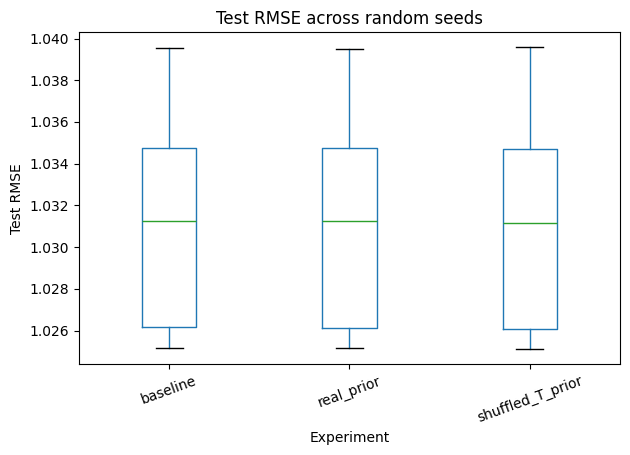

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

multi_seed_df.boxplot(
    column="test_rmse",
    by="experiment",
    grid=False
)

plt.title("Test RMSE across random seeds")
plt.suptitle("")
plt.xlabel("Experiment")
plt.ylabel("Test RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [138]:
pivot = multi_seed_df.pivot(
    index="seed",
    columns="experiment",
    values="test_rmse"
).reset_index()

pivot["real_gain_vs_baseline"] = (
    pivot["baseline"] - pivot["real_prior"]
)

pivot["shuffled_gain_vs_baseline"] = (
    pivot["baseline"] - pivot["shuffled_T_prior"]
)

pivot["real_extra_gain_over_shuffled"] = (
    pivot["shuffled_T_prior"] - pivot["real_prior"]
)

pivot

experiment,seed,baseline,real_prior,shuffled_T_prior,real_gain_vs_baseline,shuffled_gain_vs_baseline,real_extra_gain_over_shuffled
0,0,1.039548,1.039500,1.039575,0.000048,-0.000027,0.000075
1,1,1.034763,1.034750,1.034698,0.000013,0.000064,-0.000052
2,2,1.026169,1.026133,1.026073,0.000036,0.000096,-0.000060
3,3,1.031245,1.031229,1.031147,0.000015,0.000098,-0.000083
4,4,1.025185,1.025169,1.025101,0.000017,0.000085,-0.000068
